<a href="https://colab.research.google.com/github/adityamkoundinya-stack/3rd-sem-hacakthon-/blob/main/Automotive_Model_1_Machine_Failure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

import requests
import zipfile
import io

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print(z.namelist())
    csv_file = next(
        name for name in z.namelist()
        if name.endswith(".csv")
    )
    df = pd.read_csv(z.open(csv_file))

print("Dataset downloaded!")
print("Shape:", df.shape)
df.head()


['ai4i2020.csv']
Dataset downloaded!
Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nFailure Distribution:")
print(df["Machine failure"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes:

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000



Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


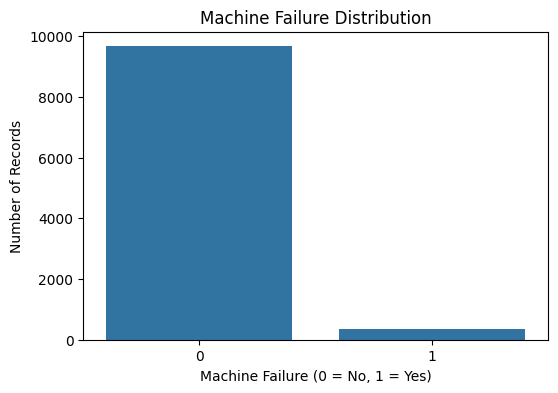

In [4]:

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Machine failure")
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()


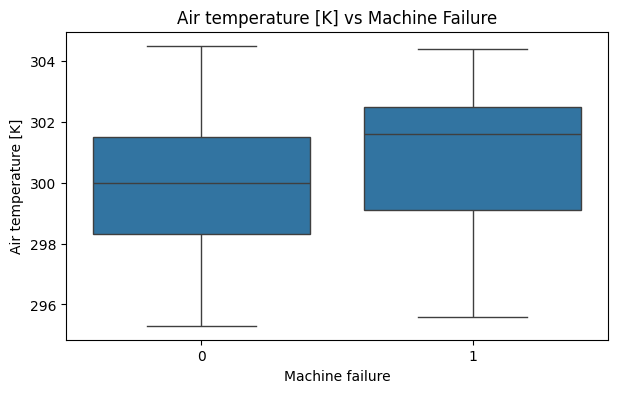

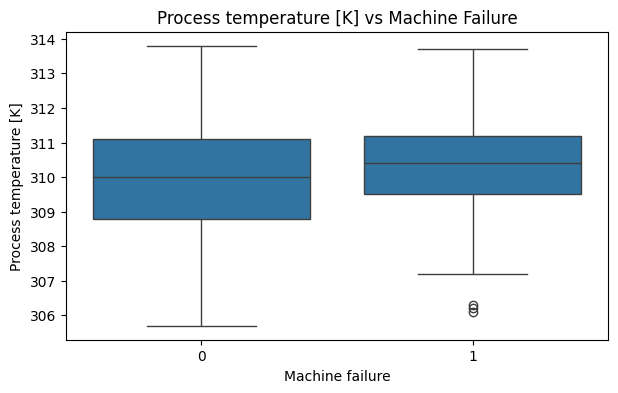

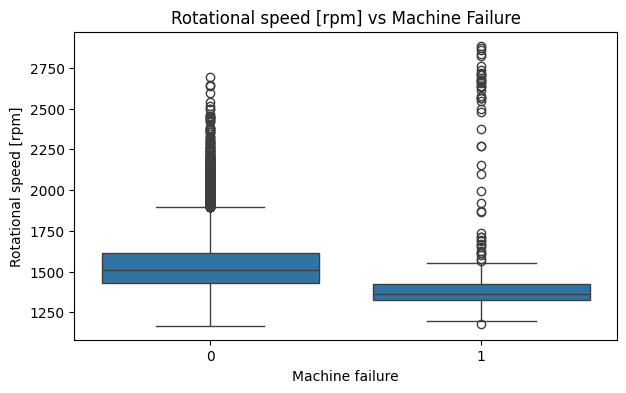

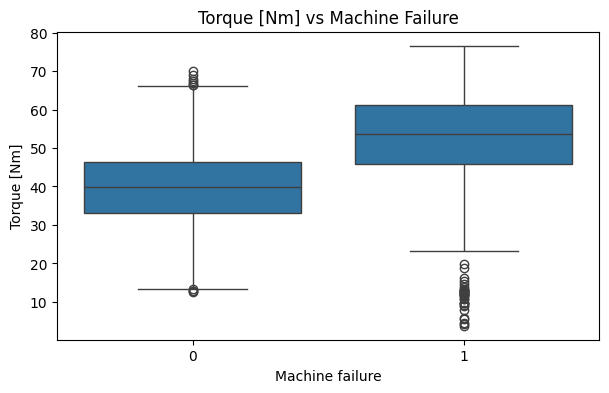

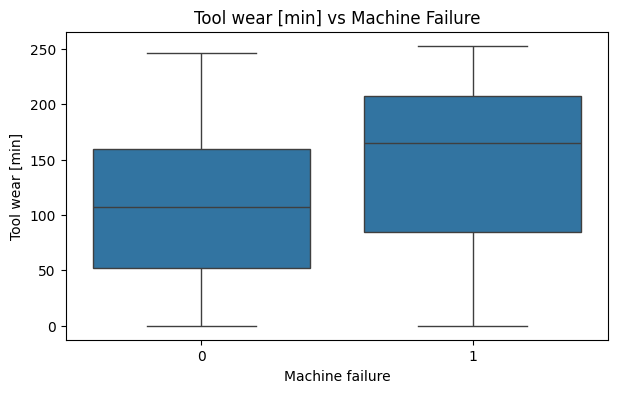

In [5]:

features_to_plot = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for feature in features_to_plot:
    plt.figure(figsize=(7,4))
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature
    )
    plt.title(f"{feature} vs Machine Failure")
    plt.show()



In [6]:

X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 8000
Testing records: 2000


In [7]:

categorical_features = ["Type"]

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "numeric",
        StandardScaler(),
        numeric_features
    )
])


In [8]:

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "training completed!")


Logistic Regression training completed!
Random Forest training completed!


In [9]:

for name, model in trained_models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1 Score:", f1_score(y_test, predictions))

    print(
        "PR-AUC:",
        average_precision_score(y_test, probabilities)
    )

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))



Logistic Regression
Accuracy: 0.8245
Precision: 0.14177215189873418
Recall: 0.8235294117647058
F1 Score: 0.24190064794816415
PR-AUC: 0.38176196610560775

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000


Random Forest
Accuracy: 0.9805
Precision: 0.9142857142857143
Recall: 0.47058823529411764
F1 Score: 0.6213592233009708
PR-AUC: 0.7752590913041436

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.91      0.47      0.62        68

    accuracy                           0.98      2000
   macro avg       0.95      0.73      0.81      2000
weighted avg       0.98      0.98      0.98      2000

In [10]:

best_model = trained_models["Random Forest"]

joblib.dump(
    best_model,
    "automotive_machine_failure.pkl"
)

print("Machine failure model saved!")


Machine failure model saved!


In [12]:

new_machine = pd.DataFrame([{
    "Type": "M",
    "Air temperature [K]": 313,
    "Process temperature [K]": 310,
    "Rotational speed [rpm]": 1400,
    "Torque [Nm]": 35,
    "Tool wear [min]": 180
}])

failure_probability = best_model.predict_proba(
    new_machine
)[0][1]

print("Failure probability:",
      round(failure_probability * 100, 2), "%")

print(
    "Predicted failure:",
    int(failure_probability >= 0.5)
)


Failure probability: 3.67 %
Predicted failure: 0


In [16]:
y_pred = best_model.predict(X_test)

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("MODEL 1 - MACHINE FAILURE PREDICTION")
print("------------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

MODEL 1 - MACHINE FAILURE PREDICTION
------------------------------------
Accuracy: 0.9805
Precision: 0.9142857142857143
Recall: 0.47058823529411764
F1 Score: 0.6213592233009708

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.91      0.47      0.62        68

    accuracy                           0.98      2000
   macro avg       0.95      0.73      0.81      2000
weighted avg       0.98      0.98      0.98      2000


Confusion Matrix:
[[1929    3]
 [  36   32]]
